In [812]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.transform import  resize
from skimage import io, morphology
from skimage import io, filters
from PIL import Image
import skimage.io as io


In [813]:
# Upload Images
rgb_image=io.imread('/content/OIP (1).jpg')
image2=io.imread('/content/image2.jpg')
image3=io.imread('/content/image3.jpg')

In [814]:
#Convert RGB image To Grayscale
height, width, channel = rgb_image.shape
gray_image = np.zeros((height, width), dtype=np.uint8)

In [815]:
for i in range(height):
    for j in range(width):
        r, g, b = map(int, rgb_image[i, j])
        gray_image[i, j] = int((r + g + b) / 3)

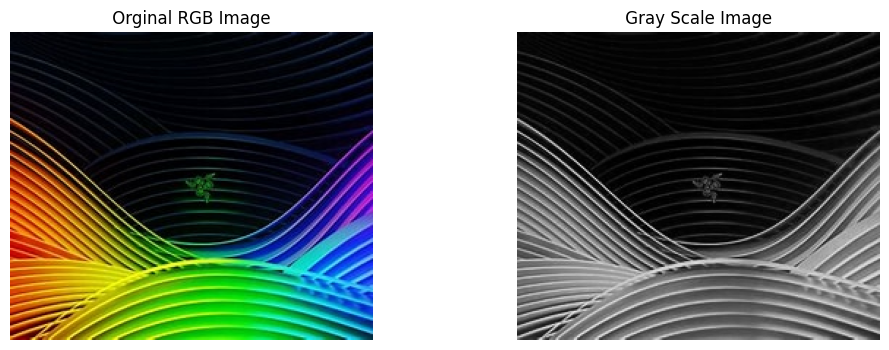

In [816]:
fig, ax = plt.subplots(1, 2, figsize=(12,4))
ax[0].imshow(rgb_image)
ax[0].set_title(" Orginal RGB Image ")
ax[0].axis("off")
ax[1].imshow(gray_image , cmap="gray")
ax[1].set_title(" Gray Scale Image ")
ax[1].axis("off")
plt.show()

In [817]:
#⁠Brightness (Addation)
image1 = io.imread('/content/OIP (1).jpg', as_gray=True)
image1 = (image1 * 255).astype(np.uint8)

In [818]:
bright_constant = 100
bright_image1 = np.zeros_like(image1)
height, width = image1.shape

In [819]:
for i in range(height):
    for j in range(width):
        pixel = int(image1[i, j])
        bright_value = pixel + bright_constant
        bright_image1[i, j] = min(bright_value, 255)

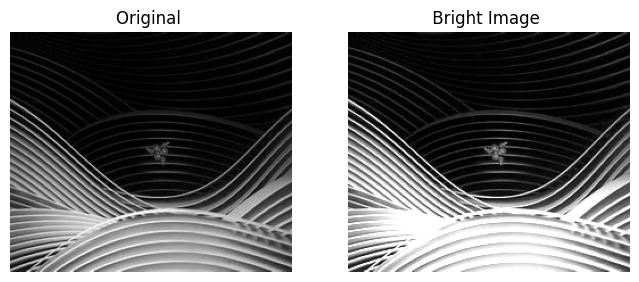

In [820]:
fig , axis=plt.subplots(1,2, figsize=(8,12))
axis[0].imshow(image1, cmap='gray')
axis[0].set_title("Original ")
axis[0].axis("off")
axis[1].imshow(bright_image1, cmap='gray')
axis[1].set_title(" Bright Image  ")
axis[1].axis("off")
plt.show()


In [821]:
# (Multiplication )


In [822]:
bright_constant = 2
bright_image1 = np.zeros_like(gray_image)
height, width = image1.shape

for i in range(height):
    for j in range(width):
        pixel = int(gray_image[i, j])
        bright_value = pixel * bright_constant
        bright_image1[i, j] = min(bright_value, 255)

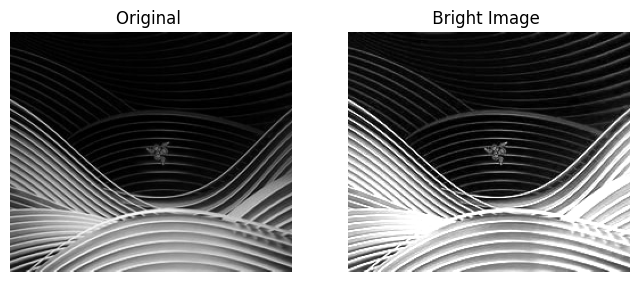

In [823]:
fig , axis=plt.subplots(1,2, figsize=(8,12))
axis[0].imshow(image1, cmap='gray')
axis[0].set_title("Original ")
axis[0].axis("off")
axis[1].imshow(bright_image1, cmap='gray')
axis[1].set_title(" Bright Image  ")
axis[1].axis("off")
plt.show()

In [824]:
#Subtraction

In [825]:
dark_constant = 50
dark_image1 = np.zeros_like(image1)
height, width = image1.shape

In [826]:
for i in range(height):
    for j in range(width):
        pixel = int(image1[i, j])
        dark_value = pixel - dark_constant
        dark_image1[i, j] = max(dark_value, 0)

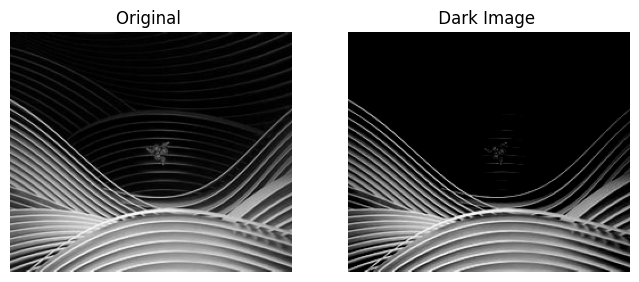

In [827]:
fig , axis=plt.subplots(1,2, figsize=(8,12))
axis[0].imshow(image1, cmap='gray')
axis[0].set_title("Original ")
axis[0].axis("off")
axis[1].imshow(dark_image1, cmap='gray')
axis[1].set_title(" Dark Image  ")
axis[1].axis("off")
plt.show()

In [828]:
#division

In [829]:
for i in range(height):
    for j in range(width):
        pixel = int(image1[i, j])
        dark_value = pixel / dark_constant
        dark_image1[i, j] = int(max(dark_value, 0))

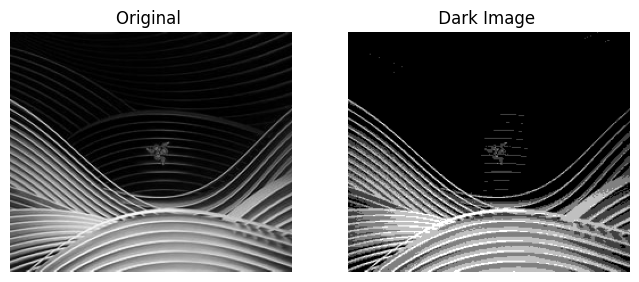

In [830]:
fig , axis=plt.subplots(1,2, figsize=(8,12))
axis[0].imshow(image1, cmap='gray')
axis[0].set_title("Original ")
axis[0].axis("off")
axis[1].imshow(dark_image1, cmap='gray')
axis[1].set_title(" Dark Image  ")
axis[1].axis("off")
plt.show()

In [831]:
#Subtract two Images

In [832]:
image3 =resize(image3, image2.shape)
image3 =(resize(image3, image2.shape) * 255).astype(np.uint8)
subtracted1_image =np.zeros_like(image2)
subtracted2_image =np.zeros_like(image2)
height, width, channels =image2.shape


In [833]:
for i in range(height):
        for j in range(width):
            for c in range(3):
                subtract = int(image2[i][j][c]) - int(image3[i][j][c])
                subtracted1_image[i][j][c] = max(subtract, 0)

In [834]:
for i in range(height):
        for j in range(width):
            for c in range(3):
                subtract = int(image3[i][j][c]) - int(image2[i][j][c])
                subtracted2_image[i][j][c] = max(subtract, 0)

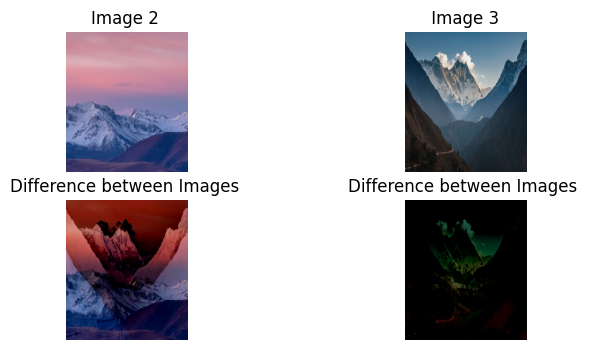

In [835]:
fig , axis=plt.subplots(2,2, figsize=(8,4))
axis[0][0].imshow(image2)
axis[0][0].set_title("Image 2 ")
axis[0][0].axis("off")
axis[0][1].imshow(image3)
axis[0][1].set_title(" Image 3 ")
axis[0][1].axis("off")
axis[1][0].imshow(subtracted1_image)
axis[1][0].set_title("Difference between Images ")
axis[1][0].axis("off")
axis[1][1].imshow(subtracted2_image)
axis[1][1].set_title("Difference between Images ")
axis[1][1].axis("off")
plt.show()

In [836]:
#Image Histogram ( Gray  )

In [837]:
histogram = np.zeros(256, dtype=int)


In [838]:
height, width = gray_image.shape


In [839]:
for i in range(height):
    for j in range(width):
        intensity = gray_image[i, j]
        histogram[intensity] += 1

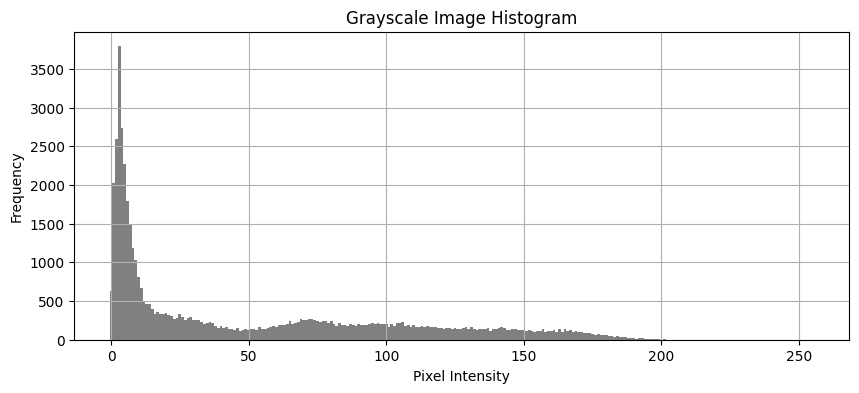

In [840]:
plt.figure(figsize=(10, 4))
plt.bar(range(256), histogram, width=1.0, color='gray')
plt.title("Grayscale Image Histogram")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.grid(True)
plt.show()

In [841]:
#Histogram stretching


In [842]:
def compute_histogram(image):
    histogram = np.zeros(256, dtype=int)

    height, width = image.shape
    for i in range(height):
        for j in range(width):
            intensity = image[i, j]
            histogram[intensity] += 1
    return histogram

In [843]:
def histogram_streching(image):

    height, width = image.shape

    I_min = 255
    I_max = 0

    for i in range(height):
        for j in range(width):
            pixel = image[i][j]
            if pixel < I_min:
                I_min = pixel
            if pixel > I_max:
                I_max = pixel

    stretched = np.zeros((height, width), dtype=np.uint8)
    for i in range(height):
        for j in range(width):
            pixel = image[i][j]
            new_pixel =int((int(pixel) - int(I_min)) * 255 /(int(I_max) - int(I_min)))
            stretched[i][j] = min(max(new_pixel, 0), 255)

    return stretched

In [844]:
original_histogram = compute_histogram(gray_image)
enhanced_image = histogram_streching(gray_image)
enhanced_histogram = compute_histogram(enhanced_image)


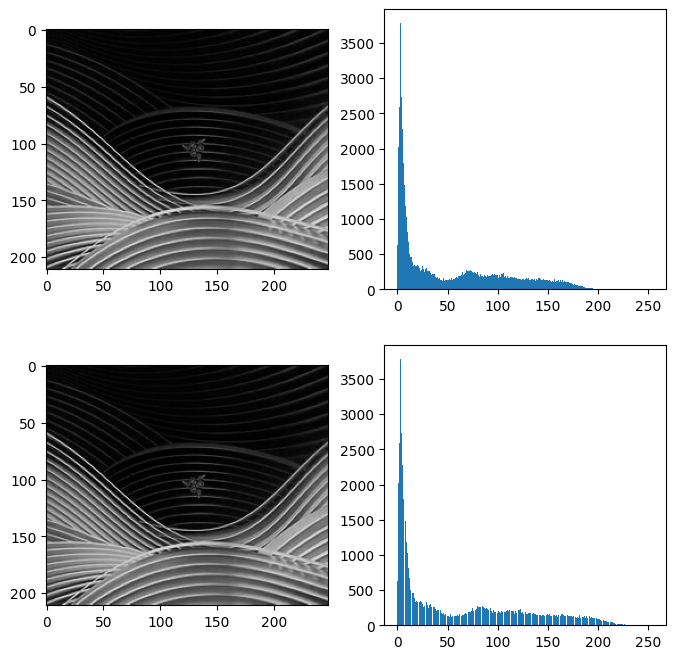

In [845]:
fig, ax = plt.subplots(2, 2, figsize=(8, 8))
ax[0][0].imshow(gray_image, cmap='gray')
ax[0][1].bar(range(256), original_histogram)
ax[1][0].imshow(enhanced_image, cmap='gray')
ax[1][1].bar(range(256), enhanced_histogram)
plt.show()

In [846]:
#histogram_equalization

In [847]:
def compute_histogram(gray_image):
    hist = np.zeros(256, dtype=int)
    h, w = gray_image.shape
    for i in range(h):
        for j in range(w):
            hist[int(gray_image[i, j])] += 1
    return hist

In [848]:
def histogram_equalization(gray_image):
    hist = compute_histogram(gray_image)

    cdf = np.cumsum(hist).astype(float)
    cdf = cdf / cdf[-1]

    lut = (cdf * 255).astype(np.uint8)

    h, w = gray_image.shape
    out = np.zeros_like(gray_image, dtype=np.uint8)

    for i in range(h):
        for j in range(w):
            out[i, j] = lut[int(gray_image[i, j])]

    return out, hist, compute_histogram(out)


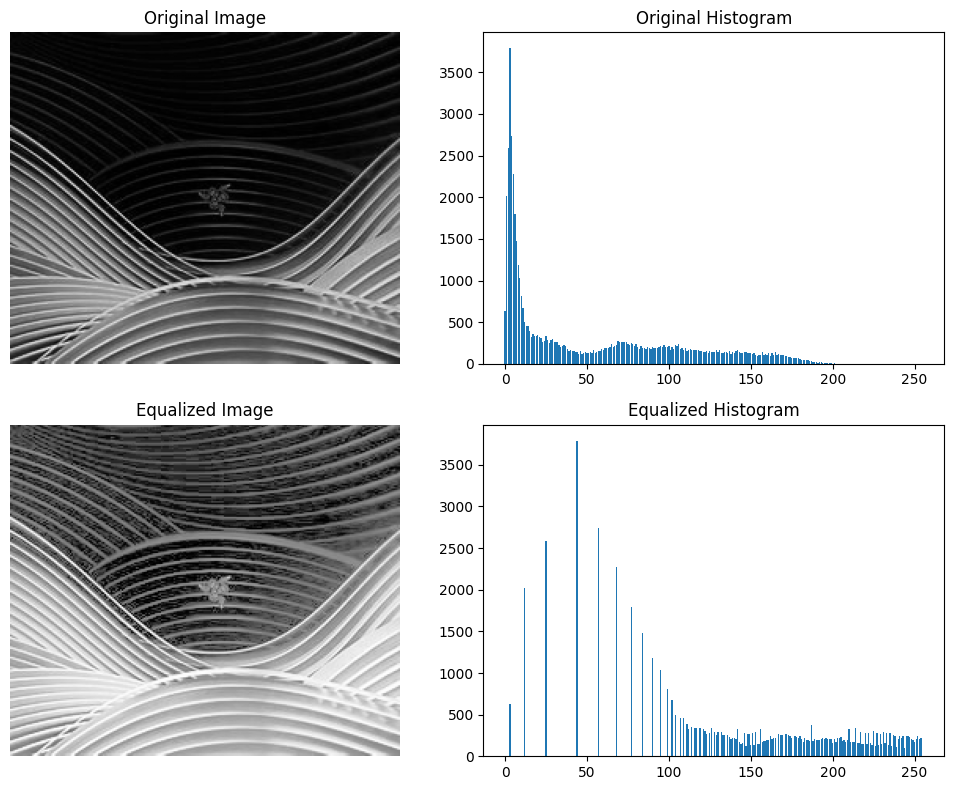

In [849]:
equalized_image, old_hist, new_hist = histogram_equalization(gray_image)

fig, ax = plt.subplots(2, 2, figsize=(10, 8))

ax[0][0].imshow(gray_image, cmap='gray')
ax[0][0].set_title("Original Image")
ax[0][0].axis('off')

ax[0][1].bar(range(256), old_hist)
ax[0][1].set_title("Original Histogram")

ax[1][0].imshow(equalized_image, cmap='gray')
ax[1][0].set_title("Equalized Image")
ax[1][0].axis('off')

ax[1][1].bar(range(256), new_hist)
ax[1][1].set_title("Equalized Histogram")

plt.tight_layout()
plt.show()


In [850]:
## Mean Filter

In [851]:
def mean_filter(image, zero_padding=True):
    height, width = image.shape

    if zero_padding:
        padded_image = np.zeros((height + 2, width + 2), dtype=np.uint8)
        padded_image[1:-1, 1:-1] = image
        unfiltered_image = padded_image
        filtered_image = np.zeros((height, width), dtype=np.uint8)
        rows, cols = height + 1, width + 1
    else:
        unfiltered_image = image
        filtered_image = np.zeros((height - 2, width - 2), dtype=np.uint8)
        rows, cols = height - 1, width - 1

    for i in range(1, rows):
        for j in range(1, cols):
            neighbor = [unfiltered_image[i-1, j-1],   unfiltered_image[i-1, j],   unfiltered_image[i-1, j + 1],
                        unfiltered_image[i, j-1],     unfiltered_image[i, j],     unfiltered_image[i, j + 1],
                        unfiltered_image[i + 1, j-1], unfiltered_image[i + 1, j], unfiltered_image[i + 1, j + 1]]
            avg = sum(map(int,neighbor)) // 9
            filtered_image[i - 1, j - 1] = avg

    return filtered_image

original image1 shape:(211, 248), mean filtered image1 shape:(209, 246)


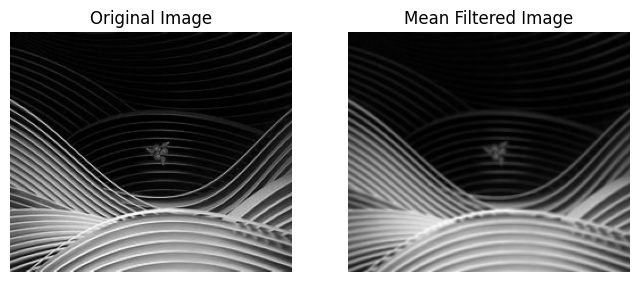

In [852]:
mean_img = mean_filter(image1, False)

print(f'original image1 shape:{image1.shape}, mean filtered image1 shape:{mean_img.shape}')

fig, ax = plt.subplots(1,2, figsize=(8,8))
ax[0].imshow(image1, cmap='gray')
ax[0].axis('off')
ax[0].set_title('Original Image')
ax[1].imshow(mean_img, cmap='gray')
ax[1].axis('off')
ax[1].set_title('Mean Filtered Image')
plt.show()

In [853]:
# Median Filter


In [854]:
def median_filter(image, zero_padding=True):
    height, width = image.shape

    if zero_padding:
        padded_image = np.zeros((height + 2, width + 2), dtype=np.uint8)
        padded_image[1:-1, 1:-1] = image
        unfiltered_image = padded_image
        filtered_image = np.zeros((height, width), dtype=np.uint8)
        rows, cols = height + 1, width + 1
    else:
        unfiltered_image = image
        filtered_image = np.zeros((height - 2, width - 2), dtype=np.uint8)
        rows, cols = height - 1, width - 1

    for i in range(1, rows):
        for j in range(1, cols):
            neighbor = [unfiltered_image[i-1, j-1],   unfiltered_image[i-1, j],   unfiltered_image[i-1, j + 1],
                        unfiltered_image[i, j-1],     unfiltered_image[i, j],     unfiltered_image[i, j + 1],
                        unfiltered_image[i + 1, j-1], unfiltered_image[i + 1, j], unfiltered_image[i + 1, j + 1]]
            neighbor.sort()
            filtered_image[i - 1, j - 1] = neighbor[4]

    return filtered_image

original image shape:(211, 248), median filtered image shape:(211, 248)


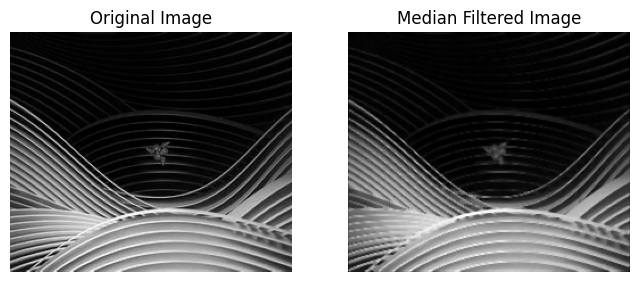

In [855]:
median_img = median_filter(image1, True)
print(f'original image shape:{image1.shape}, median filtered image shape:{median_img.shape}')

fig, ax = plt.subplots(1,2, figsize=(8,8))
ax[0].imshow(image1, cmap='gray')
ax[0].axis('off')
ax[0].set_title('Original Image')
ax[1].imshow(median_img, cmap='gray')
ax[1].axis('off')
ax[1].set_title('Median Filtered Image')
plt.show()

In [856]:
## Min Filter


In [857]:
def min_filter(image, zero_padding=True):
    height, width = image.shape

    if zero_padding:
        padded_image = np.zeros((height + 2, width + 2), dtype=np.uint8)
        padded_image[1:-1, 1:-1] = image
        unfiltered_image = padded_image
        filtered_image = np.zeros((height, width), dtype=np.uint8)
        rows, cols = height + 1, width + 1
    else:
        unfiltered_image = image
        filtered_image = np.zeros((height - 2, width - 2), dtype=np.uint8)
        rows, cols = height - 1, width - 1

    for i in range(1, rows):
        for j in range(1, cols):
            neighbor = [unfiltered_image[i-1, j-1],   unfiltered_image[i-1, j],   unfiltered_image[i-1, j + 1],
                        unfiltered_image[i, j-1],     unfiltered_image[i, j],     unfiltered_image[i, j + 1],
                        unfiltered_image[i + 1, j-1], unfiltered_image[i + 1, j], unfiltered_image[i + 1, j + 1]]
            min_val = min(neighbor)
            filtered_image[i - 1, j - 1] = min_val

    return filtered_image

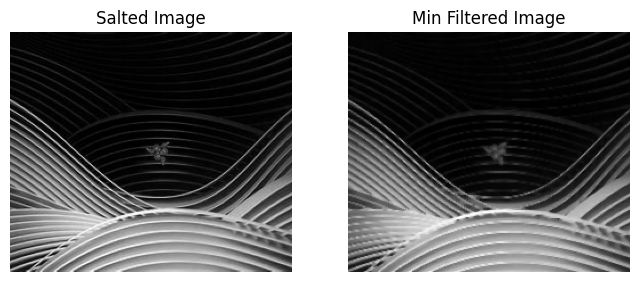

In [858]:
min_img = median_filter(image1, False)

fig, ax = plt.subplots(1,2, figsize=(8,8))
ax[0].imshow(image1, cmap='gray')
ax[0].axis('off')
ax[0].set_title('Salted Image')
ax[1].imshow(min_img, cmap='gray')
ax[1].axis('off')
ax[1].set_title('Min Filtered Image')
plt.show()

In [859]:
## Max Filter


In [860]:
def max_filter(image, zero_padding=True):
    height, width = image.shape

    if zero_padding:
        padded_image = np.zeros((height + 2, width + 2), dtype=np.uint8)
        padded_image[1:-1, 1:-1] = image
        unfiltered_image = padded_image
        filtered_image = np.zeros((height, width), dtype=np.uint8)
        rows, cols = height + 1, width + 1
    else:
        unfiltered_image = image
        filtered_image = np.zeros((height - 2, width - 2), dtype=np.uint8)
        rows, cols = height - 1, width - 1

    for i in range(1, rows):
        for j in range(1, cols):
            neighbor = [unfiltered_image[i-1, j-1],   unfiltered_image[i-1, j],   unfiltered_image[i-1, j + 1],
                        unfiltered_image[i, j-1],     unfiltered_image[i, j],     unfiltered_image[i, j + 1],
                        unfiltered_image[i + 1, j-1], unfiltered_image[i + 1, j], unfiltered_image[i + 1, j + 1]]
            max_val = max(neighbor)
            filtered_image[i - 1, j - 1] = max_val

    return filtered_image

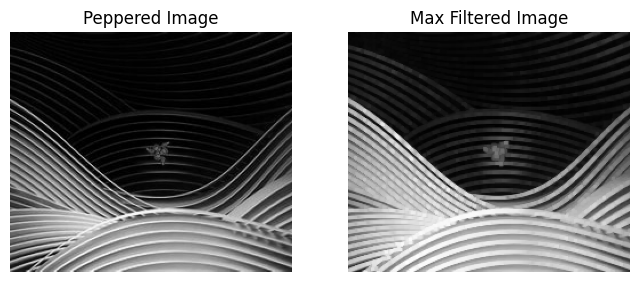

In [861]:
max_img = max_filter(image1, False)

fig, ax = plt.subplots(1,2, figsize=(8,8))
ax[0].imshow(image1, cmap='gray')
ax[0].axis('off')
ax[0].set_title('Peppered Image')
ax[1].imshow(max_img, cmap='gray')
ax[1].axis('off')
ax[1].set_title('Max Filtered Image')
plt.show()

In [862]:
#⁠Mode Filter


In [863]:
def mode_filter(image, zero_padding=True):
    height, width = image.shape

    if zero_padding:
        padded_image = np.zeros((height + 2, width + 2), dtype=np.uint8)
        padded_image[1:-1, 1:-1] = image
        unfiltered_image = padded_image
        filtered_image = np.zeros((height, width), dtype=np.uint8)
        rows, cols = height + 1, width + 1
    else:
        unfiltered_image = image
        filtered_image = np.zeros((height - 2, width - 2), dtype=np.uint8)
        rows, cols = height - 1, width - 1

    for i in range(1, rows):
        for j in range(1, cols):
            neighbor = [unfiltered_image[i-1, j-1],   unfiltered_image[i-1, j],   unfiltered_image[i-1, j + 1],
                        unfiltered_image[i, j-1],     unfiltered_image[i, j],     unfiltered_image[i, j + 1],
                        unfiltered_image[i + 1, j-1], unfiltered_image[i + 1, j], unfiltered_image[i + 1, j + 1]]

            mode_filter = max(set(neighbor), key=neighbor.count)

            filtered_image[i - 1, j - 1] = mode_filter

    return filtered_image

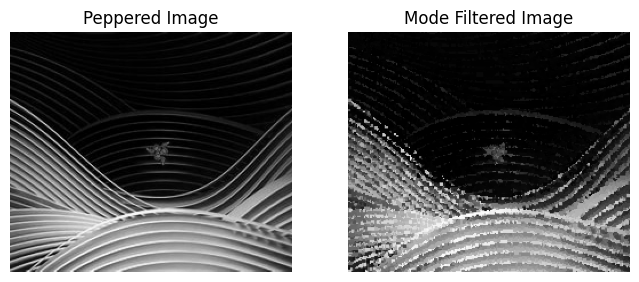

In [864]:
mode_image = mode_filter(image1, False)

fig, ax = plt.subplots(1, 2, figsize=(8, 8))

ax[0].imshow(image1, cmap='gray')
ax[0].axis('off')
ax[0].set_title('Peppered Image')

ax[1].imshow(mode_image, cmap='gray')
ax[1].axis('off')
ax[1].set_title('Mode Filtered Image')

plt.show()

In [865]:
#Range Filter


In [866]:
def range_filter(image, zero_padding=True):
    height, width = image.shape

    if zero_padding:
        padded_image = np.zeros((height + 2, width + 2), dtype=np.uint8)
        padded_image[1:-1, 1:-1] = image
        unfiltered_image = padded_image
        filtered_image = np.zeros((height, width), dtype=np.uint8)
        rows, cols = height + 1, width + 1
    else:
        unfiltered_image = image
        filtered_image = np.zeros((height - 2, width - 2), dtype=np.uint8)
        rows, cols = height - 1, width - 1

    for i in range(1, rows):
        for j in range(1, cols):
            neighbor = [unfiltered_image[i-1, j-1],   unfiltered_image[i-1, j],   unfiltered_image[i-1, j + 1],
                        unfiltered_image[i, j-1],     unfiltered_image[i, j],     unfiltered_image[i, j + 1],
                        unfiltered_image[i + 1, j-1], unfiltered_image[i + 1, j], unfiltered_image[i + 1, j + 1]]

            range_filter = max(neighbor) - min(neighbor)

            filtered_image[i - 1, j - 1] = range_filter

    return filtered_image

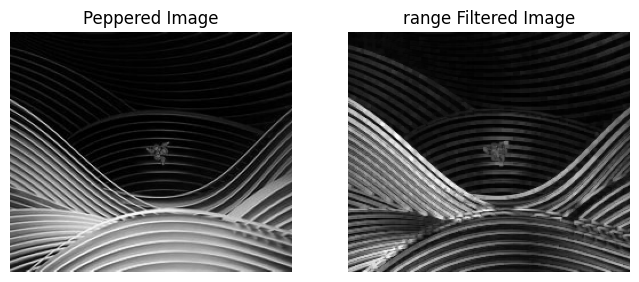

In [867]:
range_image = range_filter(image1, False)

fig, ax = plt.subplots(1, 2, figsize=(8, 8))

ax[0].imshow(image1, cmap='gray')
ax[0].axis('off')
ax[0].set_title('Peppered Image')

ax[1].imshow(range_image, cmap='gray')
ax[1].axis('off')
ax[1].set_title('range Filtered Image')

plt.show()

In [868]:
#Averaging Filter


In [869]:
def average_filter(image, zero_padding=True):
    height, width = image.shape

    if zero_padding:
        padded_image = np.zeros((height + 2, width + 2), dtype=np.uint8)
        padded_image[1:-1, 1:-1] = image
        unfiltered_image = padded_image
        filtered_image = np.zeros((height, width), dtype=np.uint8)
        rows, cols = height + 1, width + 1
    else:
        unfiltered_image = image
        filtered_image = np.zeros((height - 2, width - 2), dtype=np.uint8)
        rows, cols = height - 1, width - 1

    for i in range(1, rows):
        for j in range(1, cols):
            neighbor = [unfiltered_image[i-1, j-1],   unfiltered_image[i-1, j],   unfiltered_image[i-1, j + 1],
                        unfiltered_image[i, j-1],     unfiltered_image[i, j],     unfiltered_image[i, j + 1],
                        unfiltered_image[i + 1, j-1], unfiltered_image[i + 1, j], unfiltered_image[i + 1, j + 1]]

            average_filter =sum(map(int, neighbor)) // 9
            filtered_image[i - 1, j - 1] = average_filter

    return filtered_image

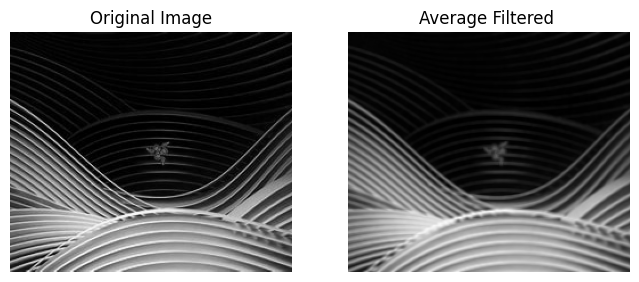

In [870]:
average_image = average_filter(image1, False)

fig, ax = plt.subplots(1, 2, figsize=(8, 8))

ax[0].imshow(image1, cmap='gray')
ax[0].axis('off')
ax[0].set_title('Original Image')

ax[1].imshow(average_image, cmap='gray')
ax[1].axis('off')
ax[1].set_title('Average Filtered ')

plt.show()

In [871]:
##Gaussian Smoothing Filter


In [872]:
def convolve(image, filter):
    h, w = image.shape
    filter_size = filter.shape[0]

    pad = filter_size // 2
    padded_img = np.zeros((h + 2*pad, w + 2*pad), dtype=np.float32)
    padded_img[pad:pad+h, pad:pad+w] = image

    filtered_img = np.zeros((h, w), dtype=np.float32)

    for i in range(h):
        for j in range(w):

            n = padded_img[i:i+filter_size, j:j+filter_size]
            conv = np.sum(n * filter)
            filtered_img[i, j] = conv

    return filtered_img.astype(np.uint8)


In [873]:
def gaussian_filter(filter_size, sigma):
    gauss_filter = np.zeros((filter_size, filter_size), np.float32)
    m = filter_size // 2
    n = filter_size // 2

    for x in range(-m, m + 1):
        for y in range(-n, n + 1):
            x1 = 2 * np.pi * (sigma ** 2)
            x2 = np.exp(-(x**2 + y**2) / (2 * sigma**2))
            gauss_filter[x + m, y + n] = (1 / x1) * x2

    return gauss_filter

In [874]:
gauss_filter_3 = np.array([[1, 2, 1],
                           [2, 4, 2],
                           [1, 2, 1]], dtype=float)
gauss_filter_3 /= gauss_filter_3.sum()

gauss_filtered_img_3 = convolve(image1, gauss_filter_3)
gauss_filtered_img_7 = convolve(image1, gaussian_filter(7, 2))



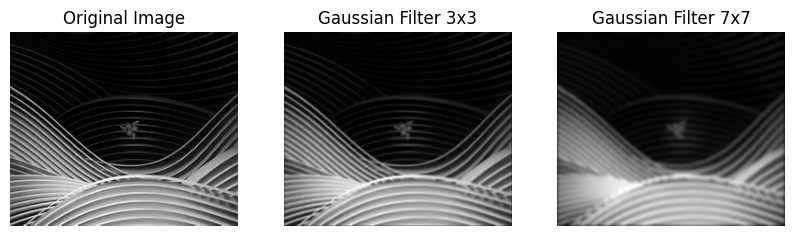

In [875]:
fig, ax = plt.subplots(1, 3, figsize=(10, 10))

ax[0].imshow(image1, cmap='gray')
ax[0].axis('off')
ax[0].set_title('Original Image')

ax[1].imshow(gauss_filtered_img_3, cmap='gray')
ax[1].axis('off')
ax[1].set_title('Gaussian Filter 3x3')

ax[2].imshow(gauss_filtered_img_7, cmap='gray')
ax[2].axis('off')
ax[2].set_title('Gaussian Filter 7x7')

plt.show()

In [876]:
# ⁠Laplacian Filter


In [877]:
def laplace_filter(filter_size, sigma):

    laplace = np.zeros((filter_size, filter_size), np.float32)
    m = filter_size // 2
    n = filter_size // 2

    for x in range(-m, m + 1):
        for y in range(-n, n + 1):
            r2 = x**2 + y**2
            sigma2 = sigma**2


            const = -1 / (np.pi * (sigma2**2))

            bracket = 1 - (r2 / (2 * sigma2))

            expon = np.exp(-r2 / (2 * sigma2))

            laplace[x + m, y + n] = const * bracket * expon

    laplace -= laplace.mean()

    return laplace


In [878]:
laplace_filter_3 = np.array([[1, -2, 1],
                            [-2, 4, -2],
                            [1, -2, 1]], dtype=float)


laplace_filtered_img_3 = convolve(image1, laplace_filter_3)

laplace_filtered_img_7 = convolve(image1, laplace_filter(7, 2))

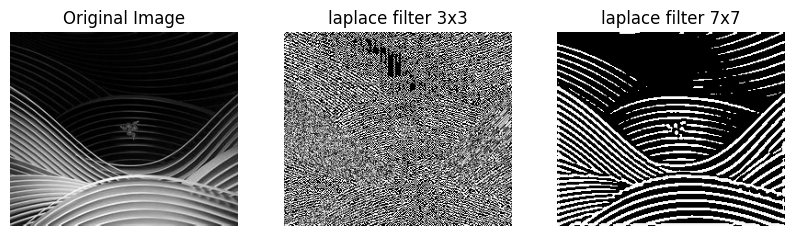

In [879]:
fig, ax = plt.subplots(1, 3, figsize=(10, 10))

ax[0].imshow(image1, cmap='gray')
ax[0].axis('off')
ax[0].set_title('Original Image')

ax[1].imshow(laplace_filtered_img_3, cmap='gray')
ax[1].axis('off')
ax[1].set_title('laplace filter 3x3')

ax[2].imshow(laplace_filtered_img_7, cmap='gray')
ax[2].axis('off')
ax[2].set_title('laplace filter 7x7')

plt.show()

In [880]:
##Add Salt&Pepper Noise To Image

In [881]:
noisy_image = image1.copy()

noise_ratio = 0.2

total_pixels =  image1.size

num_noisy_pixels = int(noise_ratio * total_pixels)


salt_positions = np.random.randint( 0, total_pixels, num_noisy_pixels)
noisy_image.flat[salt_positions] = 255

pepper_positions = np.random.randint( 0, total_pixels, num_noisy_pixels)
noisy_image.flat[pepper_positions] = 0



Text(0.5, 1.0, 'Salt & Pepper Noisy Image')

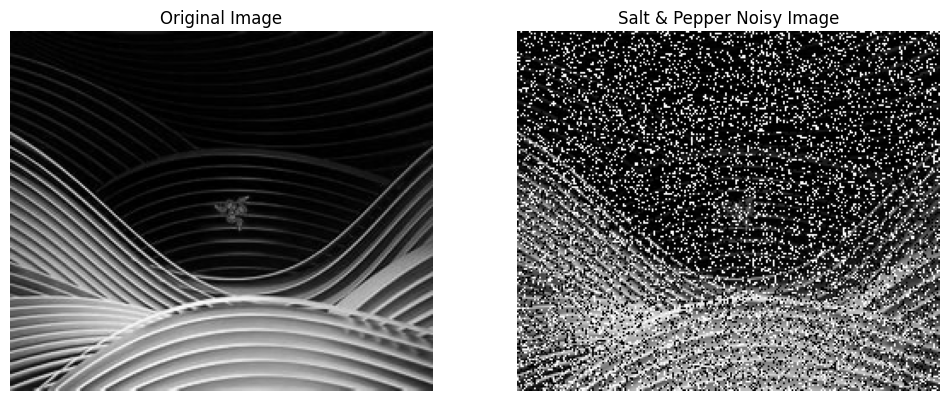

In [882]:
fig, ax = plt.subplots(1,2, figsize=(12,8))
ax[0].imshow(image1, cmap='gray')
ax[0].axis('off')
ax[0].set_title('Original Image')
ax[1].imshow(noisy_image, cmap='gray')
ax[1].axis('off')
ax[1].set_title('Salt & Pepper Noisy Image')

In [883]:
##Add Gaussian Noise to Image


In [884]:
noisy_image = image1.copy()

mean = 0     # المتوسط (0 للحفاظ على سطوع الصورة)
sigma = 25      # الانحراف المعياري (كلما زاد، زاد التشويش)

gauss = np.random.normal(mean, sigma, image1.shape)

noisy_image_float = noisy_image.astype('float32') + gauss

noisy_image = np.clip(noisy_image_float, 0, 255)

noisy_image = noisy_image.astype('uint8')

<>:7: SyntaxWarning: invalid escape sequence '\s'
<>:7: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipython-input-3603246407.py:7: SyntaxWarning: invalid escape sequence '\s'
  ax[1].set_title(f'Image with Gaussian Noise ($\sigma$={sigma})')


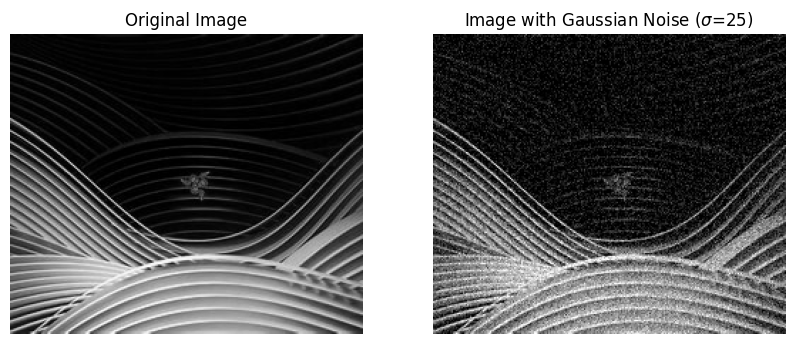

In [885]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(image1, cmap='gray')
ax[0].set_title('Original Image')
ax[0].axis('off')

ax[1].imshow(noisy_image, cmap='gray')
ax[1].set_title(f'Image with Gaussian Noise ($\sigma$={sigma})')
ax[1].axis('off')

plt.show()

In [886]:
##Add Periodic Noise

In [887]:

noisy_image = image1.copy()

amplitude = 30

frequency = 20

x = np.arange(width)
y = np.arange(height)
X, Y = np.meshgrid(x, y)


periodic_noise = amplitude * np.sin(2 * np.pi * frequency * (X / width + Y / height))


noisy_image_float = noisy_image.astype('float32') + periodic_noise

noisy_image = np.clip(noisy_image_float, 0, 255)
noisy_image = noisy_image.astype('uint8')

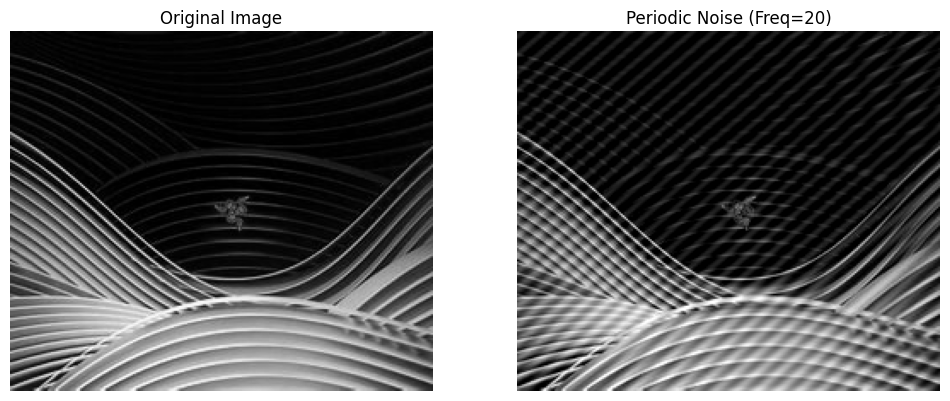

In [888]:
fig, ax = plt.subplots(1, 2, figsize=(12, 6))

ax[0].imshow(image1, cmap='gray')
ax[0].set_title('Original Image')
ax[0].axis('off')

ax[1].imshow(noisy_image, cmap='gray')
ax[1].set_title(f'Periodic Noise (Freq={frequency})')
ax[1].axis('off')

plt.show()

In [889]:
##Dilation

(np.float64(-0.5), np.float64(247.5), np.float64(210.5), np.float64(-0.5))

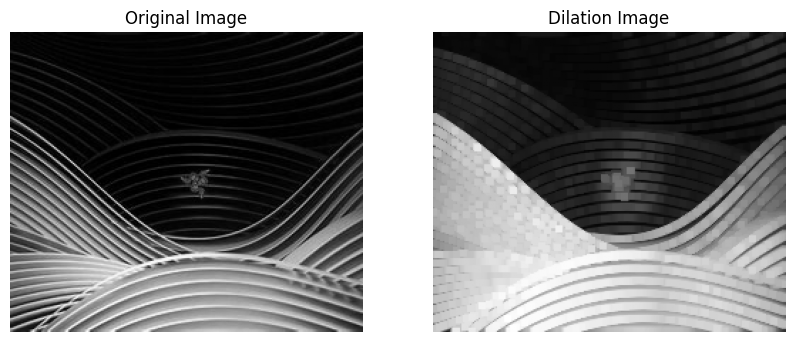

In [890]:
structure_element = np.ones((5,5),dtype=np.uint8)
Dilation = morphology.dilation(image1, structure_element)
fig , ax = plt.subplots(1,2,figsize=(10,10))
ax[0].imshow(image1,cmap='gray')
ax[0].set_title("Original Image")
ax[0].axis('off')
ax[1].imshow(Dilation,cmap='gray')
ax[1].set_title("Dilation Image")
ax[1].axis('off')

In [891]:
#Erosion

(np.float64(-0.5), np.float64(247.5), np.float64(210.5), np.float64(-0.5))

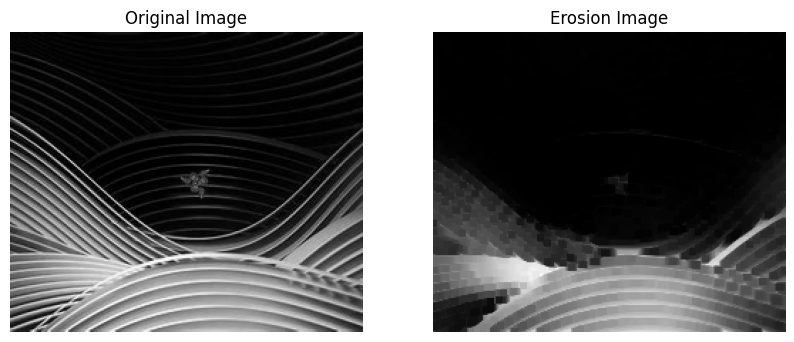

In [892]:

Erosion = morphology.erosion(image1, structure_element)
fig , ax = plt.subplots(1,2,figsize=(10,10))
ax[0].imshow(image1,cmap='gray')
ax[0].set_title("Original Image")
ax[0].axis('off')
ax[1].imshow(Erosion,cmap='gray')
ax[1].set_title("Erosion Image")
ax[1].axis('off')


In [893]:
#Opening

(np.float64(-0.5), np.float64(247.5), np.float64(210.5), np.float64(-0.5))

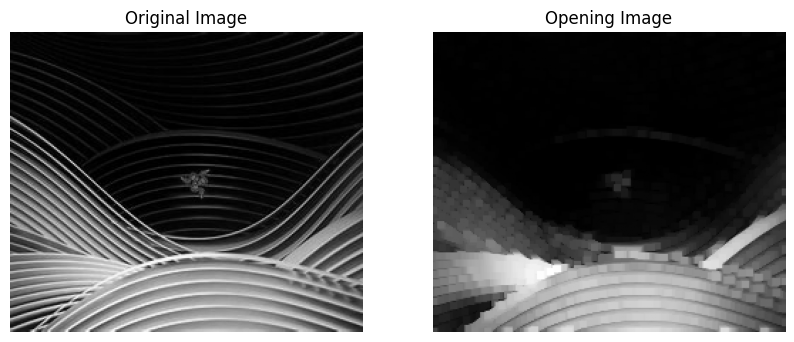

In [894]:
opened = morphology.opening(image1, structure_element)
fig , ax = plt.subplots(1,2,figsize=(10,10))
ax[0].imshow(image1,cmap='gray')
ax[0].set_title("Original Image")
ax[0].axis('off')
ax[1].imshow(opened,cmap='gray')
ax[1].set_title("Opening Image")
ax[1].axis('off')

In [895]:
#Closing

(np.float64(-0.5), np.float64(247.5), np.float64(210.5), np.float64(-0.5))

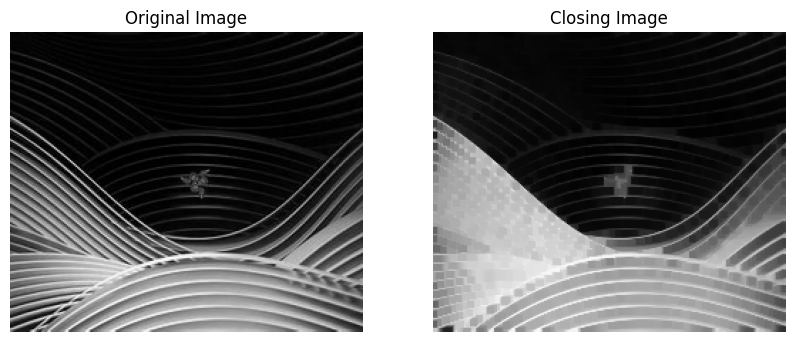

In [896]:
closed = morphology.closing(image1, structure_element)
fig , ax = plt.subplots(1,2,figsize=(10,10))
ax[0].imshow(image1,cmap='gray')
ax[0].set_title("Original Image")
ax[0].axis('off')
ax[1].imshow(closed,cmap='gray')
ax[1].set_title("Closing Image")
ax[1].axis('off')


In [897]:
##opened , closed

Text(0.5, 1.0, 'Closed')

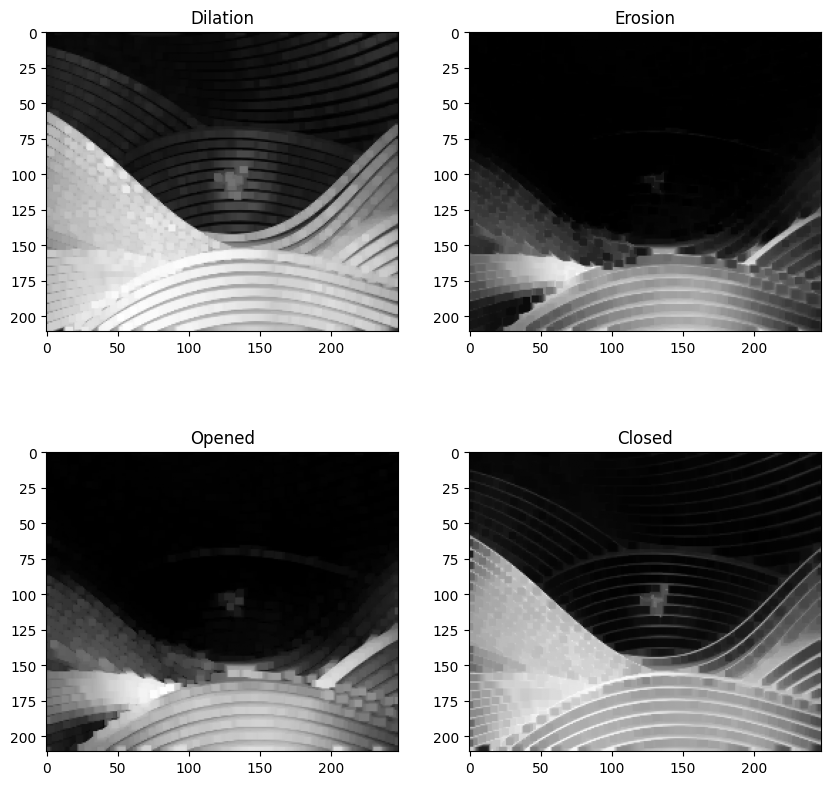

In [898]:
fig , ax = plt.subplots(2,2,figsize=(10,10))

ax[0][0].imshow(Dilation,cmap='gray')
ax[0][0].set_title('Dilation')
ax[0][1].imshow(Erosion,cmap='gray')
ax[0][1].set_title('Erosion')
ax[1][0].imshow(opened,cmap='gray')
ax[1][0].set_title('Opened')
ax[1][1].imshow(closed,cmap='gray')
ax[1][1].set_title('Closed')


In [899]:
# - ⁠Automatic Thresholding (Segmentation)


In [900]:
image1 = io.imread('/content/OIP (1).jpg', as_gray=True)


T = filters.threshold_otsu(image1)

binary = image1 >= T




In [901]:
print(type(image1))

<class 'numpy.ndarray'>


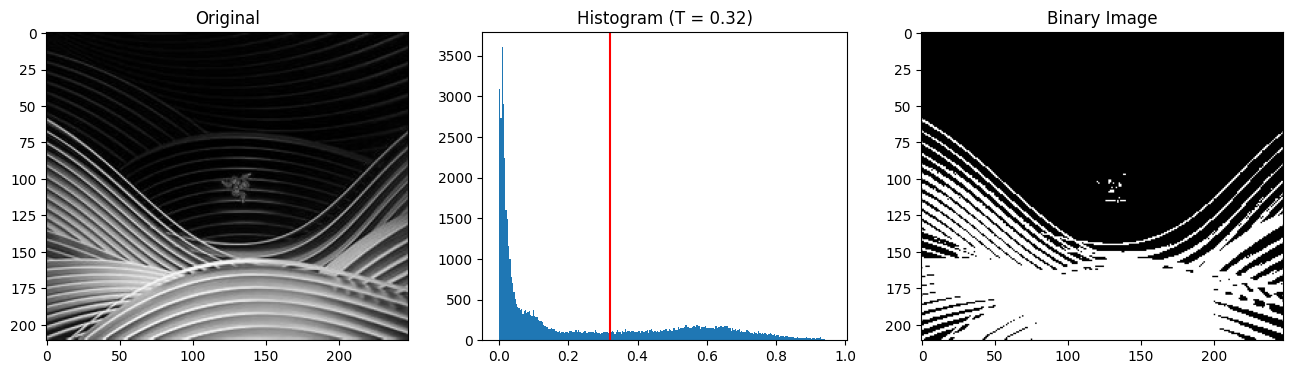

In [902]:
fig, ax = plt.subplots(1,3, figsize=(16,4))
ax[0].imshow(image1, cmap="gray")
ax[0].set_title("Original")

ax[1].hist(image1.ravel(), bins=256)
ax[1].axvline(T, color='red')
ax[1].set_title(f"Histogram (T = {T:.2f})")

ax[2].imshow(binary, cmap="gray")
ax[2].set_title("Binary Image")
plt.show()

In [903]:
# - ⁠ Dithering

In [904]:
image1 = Image.open('/content/OIP (1).jpg').convert('L')
#image1 = Image.open('/content/OIP (1).jpg')

dithered = image1.convert('1', dither=Image.FLOYDSTEINBERG)


In [905]:
print(type(image1))

<class 'PIL.Image.Image'>


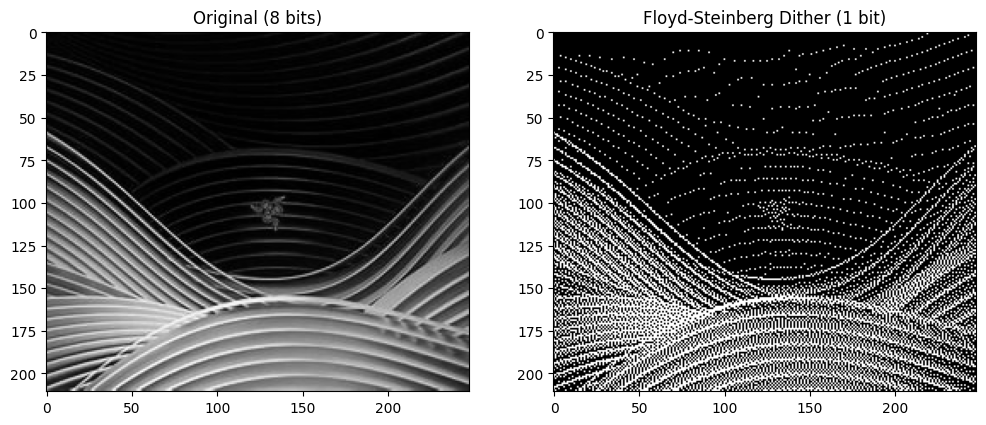

In [906]:
fig, ax = plt.subplots(1,2, figsize=(12,8))
ax[0].imshow(image1, cmap="gray")
ax[0].set_title("Original (8 bits)")

ax[1].imshow(dithered, cmap="binary")
ax[1].set_title("Floyd-Steinberg Dither (1 bit)")
plt.show()